# Part D · The clinical review figure

**Ali Afzal** · BSAI-7B-102 · Data Visualization · Week 3

A clinical analytics group has to inspect 10,000 vital-sign records before a safety review: find the
data-entry anomalies, check which measures aren't normally distributed, and spot correlated risk
indicators. This notebook audits `vitals_10k.csv`, states a rule for each problem, and builds one 2×2
figure exported at 300 dpi to [`charts/partD_figure.png`](charts/partD_figure.png).

In [1]:
import textwrap
from pathlib import Path

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from vizlib import MARKERS, PALETTE, save_fig, simulate_cvd, style_defaults

DATA = Path("data")
CHARTS = Path("charts")
CHARTS.mkdir(exist_ok=True)
style_defaults(dpi=100)
BLUE, ORANGE, GREEN = PALETTE["series"]
GREY, INK, SOFT = PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]
LOG = {}

## 1 · Look before plotting

The four calls from the brief, in order.

In [2]:
raw = pd.read_csv(DATA / "vitals_10k.csv")
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   patient_id      10000 non-null  str    
 1   admit_date      10000 non-null  str    
 2   ward            10000 non-null  str    
 3   age             10000 non-null  int64  
 4   sex             10000 non-null  str    
 5   systolic        10000 non-null  int64  
 6   diastolic       10000 non-null  int64  
 7   map_mmhg        10000 non-null  float64
 8   heart_rate      10000 non-null  int64  
 9   spo2            10000 non-null  int64  
 10  bmi             10000 non-null  float64
 11  chol_mmol_l     10000 non-null  float64
 12  glucose_mmol_l  10000 non-null  float64
 13  los_days        10000 non-null  float64
 14  readmitted_30d  10000 non-null  int64  
 15  risk_score      10000 non-null  float64
dtypes: float64(6), int64(6), str(4)
memory usage: 1.2 MB


In [3]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,10000.0,58.11,16.64,18.0,47.00,58.00,69.00,97.00
systolic,10000.0,137.66,22.60,92.0,119.00,128.00,160.00,199.00
diastolic,10000.0,79.63,13.13,45.0,69.00,78.00,90.00,125.00
map_mmhg,10000.0,98.97,15.83,65.3,85.70,94.30,113.70,149.70
heart_rate,10000.0,78.83,20.56,0.0,69.00,78.00,87.00,415.00
spo2,10000.0,96.72,2.24,81.0,96.00,97.00,98.00,100.00
bmi,10000.0,66.18,191.00,0.0,24.00,27.60,31.20,999.00
chol_mmol_l,10000.0,4.82,1.01,2.1,4.14,4.82,5.51,8.79
glucose_mmol_l,10000.0,6.55,1.15,5.1,5.70,6.30,7.10,13.90
los_days,10000.0,2.31,8.92,0.0,0.61,1.38,2.57,273.65


In [4]:
raw.ward.value_counts()

ward
General Medicine    1356
general medicine    1353
Gen Medicine        1309
CARDIOLOGY           914
cardio               886
Cardiology           882
Day Surgery          749
Day-Surgery          730
Intensive Care       486
ICU                  480
 I.C.U               442
icu                  413
Name: count, dtype: int64

In [5]:
raw.admit_date.head(20).tolist()

['2026-01-19',
 '08-Mar-2026',
 '2026-02-26',
 '27/02/2026',
 '09/01/2026',
 '01-Apr-2026',
 '17-Apr-2026',
 '24-Mar-2026',
 '14-Apr-2026',
 '02-Jan-2026',
 '10/03/2026',
 '10/02/2026',
 '12-Apr-2026',
 '29/03/2026',
 '17-Apr-2026',
 '12/02/2026',
 '2026-03-28',
 '2026-02-03',
 '11-Apr-2026',
 '08/01/2026']

Four problems are visible in that output alone:

1. **`ward`** has **12 spellings for 4 wards** (`General Medicine` / `general medicine` / `Gen Medicine`,
   `ICU` / `icu` / ` I.C.U` / `Intensive Care`, …). Any `groupby` would split each ward into pieces.
2. **`admit_date`** is text in **three formats**: `2026-01-19`, `27/02/2026` and `08-Mar-2026`.
3. **`bmi`** has a maximum of **999** and a minimum of **0**. Those are "missing" codes, not body sizes, and
   they push the mean to 66.
4. **`heart_rate`** runs from **0 to 415 bpm**. Both ends are device faults.

And five more, which come from reading the data dictionary against the numbers:

5. **`map_mmhg`** is *computed* as (systolic + 2 × diastolic) / 3, so its correlation with those two is
   arithmetic.
6. **`los_days`** is extremely right-skewed: median 1.4, maximum 274 days. A linear box plot squashes to a
   line.
7. **`spo2`** sits against a physical ceiling of 100%, so a smoothed curve would leak past it (Part A
   case 9).
8. **`risk_score`** is a *ratio* (events per inpatient day). Its mean isn't the overall rate, and
   without the numerator and denominator it can't be aggregated, so it isn't used.
9. **`systolic`** is bimodal (Part A case 8). That's not an error, but it does need explaining.

## 2 · Clean it, and write down every rule

In [6]:
df = raw.copy()
LOG["rows loaded"] = f"{len(df):,}"

# 1. ward: strip, lower-case, then map every spelling onto one of four names
WARD = {"general medicine": "General Medicine", "gen medicine": "General Medicine",
        "cardiology": "Cardiology", "cardio": "Cardiology",
        "day surgery": "Day Surgery", "day-surgery": "Day Surgery",
        "intensive care": "Intensive Care", "icu": "Intensive Care", "i.c.u": "Intensive Care"}
df["ward_clean"] = df.ward.str.strip().str.lower().map(WARD)
assert df.ward_clean.nunique() == 4 and df.ward_clean.isna().sum() == 0
LOG["ward spellings conformed"] = f"{raw.ward.nunique()} spellings -> 4 wards, 0 unmatched"

# 2. admit_date: three explicit formats, each tried in turn
iso = pd.to_datetime(df.admit_date, format="%Y-%m-%d", errors="coerce")
slash = pd.to_datetime(df.admit_date, format="%d/%m/%Y", errors="coerce")
mon = pd.to_datetime(df.admit_date, format="%d-%b-%Y", errors="coerce")
df["admit_dt"] = iso.fillna(slash).fillna(mon)
is_slash = df.admit_date.str.match(r"\d\d/\d\d/")
first_gt12 = (df.admit_date[is_slash].str[:2].astype(int) > 12).mean()
second_gt12 = (df.admit_date[is_slash].str[3:5].astype(int) > 12).mean()
assert df.admit_dt.isna().sum() == 0
LOG["dates parsed"] = (f"ISO {iso.notna().sum():,}, dd/mm/yyyy {slash.notna().sum():,}, dd-Mon-yyyy {mon.notna().sum():,}; "
                       f"0 unparsed; span {df.admit_dt.min():%d %b} to {df.admit_dt.max():%d %b %Y}")
print(f"slash dates: first field > 12 in {first_gt12:.0%}, second field > 12 in {second_gt12:.0%} -> day/month")

# 3. bmi: 0 and 999 are 'missing' codes
sentinel = df.bmi.isin([0, 999])
bmi_before = df.bmi.mean()
df.loc[sentinel, "bmi"] = np.nan
LOG["bmi sentinels removed"] = (f"{(raw.bmi == 999).sum()} x 999 and {(raw.bmi == 0).sum()} x 0 -> NaN; "
                               f"mean {bmi_before:.1f} -> {df.bmi.mean():.1f} kg/m2")

# 4. heart_rate: a resting heart rate of 0 or above 250 bpm is a device fault
hr_fault = (df.heart_rate == 0) | (df.heart_rate > 250)
hr_before = df.heart_rate.mean()
df["heart_rate_raw"] = df.heart_rate
df.loc[hr_fault, "heart_rate"] = np.nan
LOG["heart-rate device faults removed"] = (f"{(raw.heart_rate > 250).sum()} readings > 250 bpm and {(raw.heart_rate == 0).sum()} "
                                          f"readings of 0 -> NaN; mean {hr_before:.2f} -> {df.heart_rate.mean():.2f} bpm")
print(f"highest heart rate kept: {df.heart_rate.max():.0f} bpm; lowest fault above 250: {raw.heart_rate[raw.heart_rate > 250].min()} bpm")

# 5. map_mmhg is derived
err = (df.map_mmhg - (df.systolic + 2 * df.diastolic) / 3).abs().max()
LOG["derived column excluded"] = f"map_mmhg = (sys + 2 dia)/3 to within {err:.2f} mmHg; left out of the heatmap"
LOG["risk_score not used"] = "a per-day ratio with no numerator/denominator; its mean is not a rate"
LOG["rows dropped entirely"] = "0 (bad values set to NaN only in the affected column)"

pd.Series(LOG, name="rule and count").to_frame()

slash dates: first field > 12 in 59%, second field > 12 in 0% -> day/month
highest heart rate kept: 135 bpm; lowest fault above 250: 331 bpm


,rule and count
rows loaded,"10,000"
ward spellings conformed,"12 spellings -> 4 wards, 0 unmatched"
dates parsed,"ISO 3,382, dd/mm/yyyy 3,253, dd-Mon-yyyy 3,365..."
bmi sentinels removed,402 x 999 and 84 x 0 -> NaN; mean 66.2 -> 27.3...
heart-rate device faults removed,29 readings > 250 bpm and 8 readings of 0 -> N...
derived column excluded,map_mmhg = (sys + 2 dia)/3 to within 0.03 mmHg...
risk_score not used,a per-day ratio with no numerator/denominator;...
rows dropped entirely,0 (bad values set to NaN only in the affected ...


The heart-rate rule isn't close to any real reading: the highest value kept is **135 bpm** and the lowest
fault is **331 bpm**, so any cut-off between them removes exactly the same 29 high readings. No row is
deleted outright. Each bad value becomes NaN in its own column only, so a patient with a faulty heart-rate
reading still counts towards blood pressure and the other columns.

### The wide file, melted

In [7]:
wide = pd.read_csv(DATA / "ward_los_wide.csv")
print(wide.shape, list(wide.columns))
los = wide.melt(var_name="ward", value_name="los_days").dropna()
los["ward"] = los.ward.replace({"Icu": "Intensive Care"})
check = pd.DataFrame({"melted wide file": los.groupby("ward").los_days.median(),
                      "vitals_10k": df.groupby("ward_clean").los_days.median()}).round(2)
print(check)
print(f"{len(los):,} stays after melt (the {wide.size - len(los):,} blank padding cells dropped); "
      f"stays of 0.00 days: {(los.los_days == 0).sum()}")

(4018, 4) ['Cardiology', 'Day Surgery', 'General Medicine', 'Icu']
                  melted wide file  vitals_10k
Cardiology                    1.69        1.69
Day Surgery                   0.25        0.25
General Medicine              1.26        1.26
Intensive Care                3.48        3.48
10,000 stays after melt (the 6,072 blank padding cells dropped); stays of 0.00 days: 2


Seaborn needs long data: one row per stay, one column per variable. `ward_los_wide.csv` has one column
per ward, padded with blanks to the longest ward. `.melt()` turns it into 10,000 rows, and the
per-ward medians match the main file exactly, so panel 2 can use either.

## 3 · Read the heatmap first: which pair is worth a scatter?

In [8]:
HEAT = ["age", "systolic", "diastolic", "heart_rate", "spo2", "bmi", "chol_mmol_l", "glucose_mmol_l", "los_days"]
corr = df[HEAT].corr()
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().dropna()
pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(5).round(3)

systolic  diastolic         0.888
age       chol_mmol_l       0.340
spo2      los_days         -0.023
age       los_days         -0.021
spo2      glucose_mmol_l    0.016
dtype: float64

Only two pairs are above |r| = 0.05. **Systolic–diastolic (0.89)** is two readings from one cuff on one
arm, which is expected and not a finding. **Age–cholesterol (0.34)** is the only correlation between two
independent measurements, and it's a recognised cardiovascular risk pairing. So it's the scatter in panel 3.

### What separates the two systolic groups?

In [9]:
hi_bp = df.systolic > 145
print(f"{hi_bp.mean():.0%} of patients above 145 mmHg")
print(pd.crosstab(df.ward_clean, hi_bp, normalize="index").round(2).rename(columns={False: "<=145", True: ">145"}))
df.groupby(hi_bp)[["age", "bmi", "glucose_mmol_l", "chol_mmol_l", "heart_rate"]].mean().round(2)

40% of patients above 145 mmHg
systolic          <=145  >145
ward_clean                   
Cardiology         0.60  0.40
Day Surgery        0.59  0.41
General Medicine   0.60  0.40
Intensive Care     0.60  0.40


,age,bmi,glucose_mmol_l,chol_mmol_l,heart_rate
systolic,,,,,
False,57.96,27.33,6.55,4.82,77.91
True,58.35,27.37,6.55,4.83,78.26


The high group is **40% of every ward**, with the same age, BMI, glucose and cholesterol as the rest.
Nothing in the file explains the split. That's a question for the clinical team (a hypertensive
sub-population, or a second measurement protocol), and the figure flags it as open instead of inventing
a cause.

## 4 · The figure

'charts\\partD_figure.png'

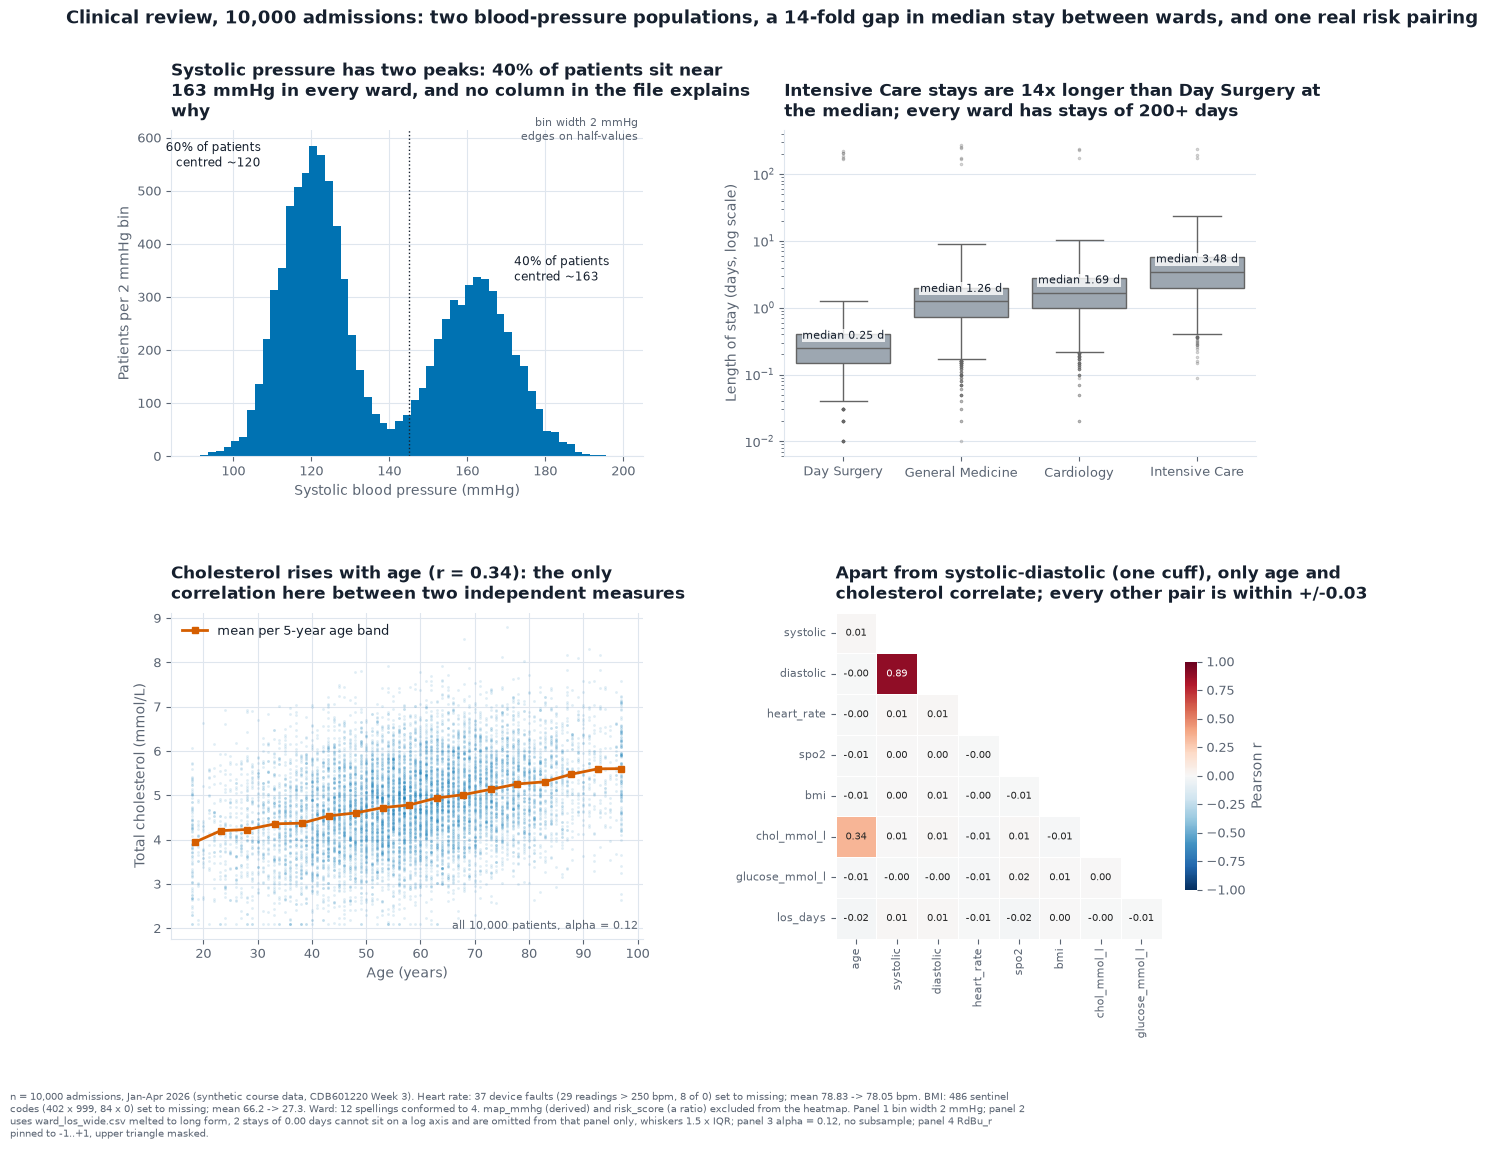

In [10]:
WARD_ORDER = los.groupby("ward").los_days.median().sort_values().index.tolist()
BINW = 2
ALPHA = 0.12


def build_figure(d, hr_col="heart_rate", label=""):
    fig, ax = plt.subplots(2, 2, figsize=(14, 10.5), gridspec_kw=dict(hspace=0.48, wspace=0.3))

    # panel 1: systolic, bin width 2 mmHg on half-value edges
    a = ax[0, 0]
    a.hist(d.systolic, bins=np.arange(89.5, 201.5, BINW), color=BLUE)
    a.axvline(145, color=INK, ls=":", lw=1)
    lo_med, hi_med = d.systolic[d.systolic <= 145].median(), d.systolic[d.systolic > 145].median()
    top = a.get_ylim()[1]
    a.text(lo_med - 13, top * 0.97, f"{(d.systolic <= 145).mean():.0%} of patients\ncentred ~{lo_med:.0f}",
           ha="right", va="top", fontsize=8.5)
    a.text(hi_med + 9, top * 0.62, f"{(d.systolic > 145).mean():.0%} of patients\ncentred ~{hi_med:.0f}",
           ha="left", va="top", fontsize=8.5)
    a.set_xlabel("Systolic blood pressure (mmHg)")
    a.set_ylabel(f"Patients per {BINW} mmHg bin")
    a.set_title(textwrap.fill(f"Systolic pressure has two peaks: {(d.systolic > 145).mean():.0%} of patients sit near "
                              f"{hi_med:.0f} mmHg in every ward, and no column in the file explains why", 58))
    a.text(0.99, 0.97, f"bin width {BINW} mmHg\nedges on half-values", transform=a.transAxes, ha="right",
           fontsize=8, color=SOFT)

    # panel 2: length of stay by ward, log scale, sorted by median
    b = ax[0, 1]
    pos = los[los.los_days > 0]
    sns.boxplot(data=pos, x="ward", y="los_days", order=WARD_ORDER, color=GREY, ax=b, log_scale=True,
                fliersize=1.5, flierprops=dict(alpha=0.35), linewidth=1)
    meds = pos.groupby("ward").los_days.median()
    for i, w in enumerate(WARD_ORDER):
        b.text(i, meds[w] * 1.25, f"median {meds[w]:.2f} d", ha="center", va="bottom", fontsize=8, color=INK,
               bbox=dict(fc="white", ec="none", pad=0.5, alpha=0.8))
    b.set_xlabel("")
    b.set_ylabel("Length of stay (days, log scale)")
    b.set_title(textwrap.fill(f"Intensive Care stays are {meds['Intensive Care'] / meds['Day Surgery']:.0f}x "
                              "longer than Day Surgery at the median; every ward has stays of 200+ days", 58))

    # panel 3: age vs cholesterol, every patient, with the age-band mean
    c = ax[1, 0]
    c.scatter(d.age, d.chol_mmol_l, s=4, alpha=ALPHA, color=BLUE, lw=0)
    band = d.groupby(pd.cut(d.age, range(15, 105, 5)), observed=True).agg(age=("age", "mean"), chol=("chol_mmol_l", "mean"))
    c.plot(band.age, band.chol, color=ORANGE, marker="s", ms=4, lw=2, label="mean per 5-year age band")
    r = d.age.corr(d.chol_mmol_l)
    c.legend(loc="upper left")
    c.set_xlabel("Age (years)")
    c.set_ylabel("Total cholesterol (mmol/L)")
    c.set_title(textwrap.fill(f"Cholesterol rises with age (r = {r:.2f}): the only correlation here "
                              "between two independent measures", 58))
    c.text(0.99, 0.03, f"all {d.chol_mmol_l.notna().sum():,} patients, alpha = {ALPHA}", transform=c.transAxes,
           ha="right", fontsize=8, color=SOFT)

    # panel 4: correlation heatmap, lower triangle, diverging, pinned to -1..+1
    e = ax[1, 1]
    cols = [h if h != "heart_rate" else hr_col for h in HEAT]
    cm = d[cols].corr().rename(index={hr_col: "heart_rate"}, columns={hr_col: "heart_rate"})
    cm = cm.iloc[1:, :-1]                       # once the diagonal is masked, its row and column are empty
    mask = np.triu(np.ones(cm.shape, bool), k=1)
    sns.heatmap(cm, mask=mask, cmap=PALETTE["diverging"], vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
                annot_kws=dict(size=7.5), linewidths=0.5, linecolor="white", square=True,
                cbar_kws=dict(shrink=0.7, label="Pearson r"), ax=e)
    e.tick_params(labelsize=8)
    e.grid(False)
    e.set_title(textwrap.fill("Apart from systolic-diastolic (one cuff), only age and cholesterol "
                              "correlate; every other pair is within +/-0.03", 58))

    for p in (a, b, c):
        for s in ("top", "right"):
            p.spines[s].set_visible(False)
    fig.suptitle("Clinical review, 10,000 admissions: two blood-pressure populations, a 14-fold gap in "
                 "median stay between wards, and one real risk pairing" + label, x=0.05, ha="left", fontsize=13, fontweight="bold", y=0.995)
    return fig


fig = build_figure(df)
note = textwrap.fill(
    f"n = 10,000 admissions, Jan-Apr 2026 (synthetic course data, CDB601220 Week 3). Heart rate: {hr_fault.sum()} device faults "
    f"(29 readings > 250 bpm, 8 of 0) set to missing; mean {hr_before:.2f} -> {df.heart_rate.mean():.2f} bpm. BMI: 486 sentinel codes "
    f"(402 x 999, 84 x 0) set to missing; mean {bmi_before:.1f} -> {df.bmi.mean():.1f}. Ward: 12 spellings conformed to 4. "
    "map_mmhg (derived) and risk_score (a ratio) excluded from the heatmap. Panel 1 bin width 2 mmHg; panel 2 uses ward_los_wide.csv "
    "melted to long form, 2 stays of 0.00 days cannot sit on a log axis and are omitted from that panel only, whiskers 1.5 x IQR; "
    f"panel 3 alpha = {ALPHA}, no subsample; panel 4 RdBu_r pinned to -1..+1, upper triangle masked.", 200)
save_fig(fig, CHARTS / "partD_figure.png", note=note)

## 5 · Appendix: the same figure without the heart-rate exclusion

This is the ethics clause in practice. The rule only touches `heart_rate`, which only appears in panel
4, so this version swaps the raw column back in.

heart_rate correlations, raw vs cleaned (largest absolute change): 0.021


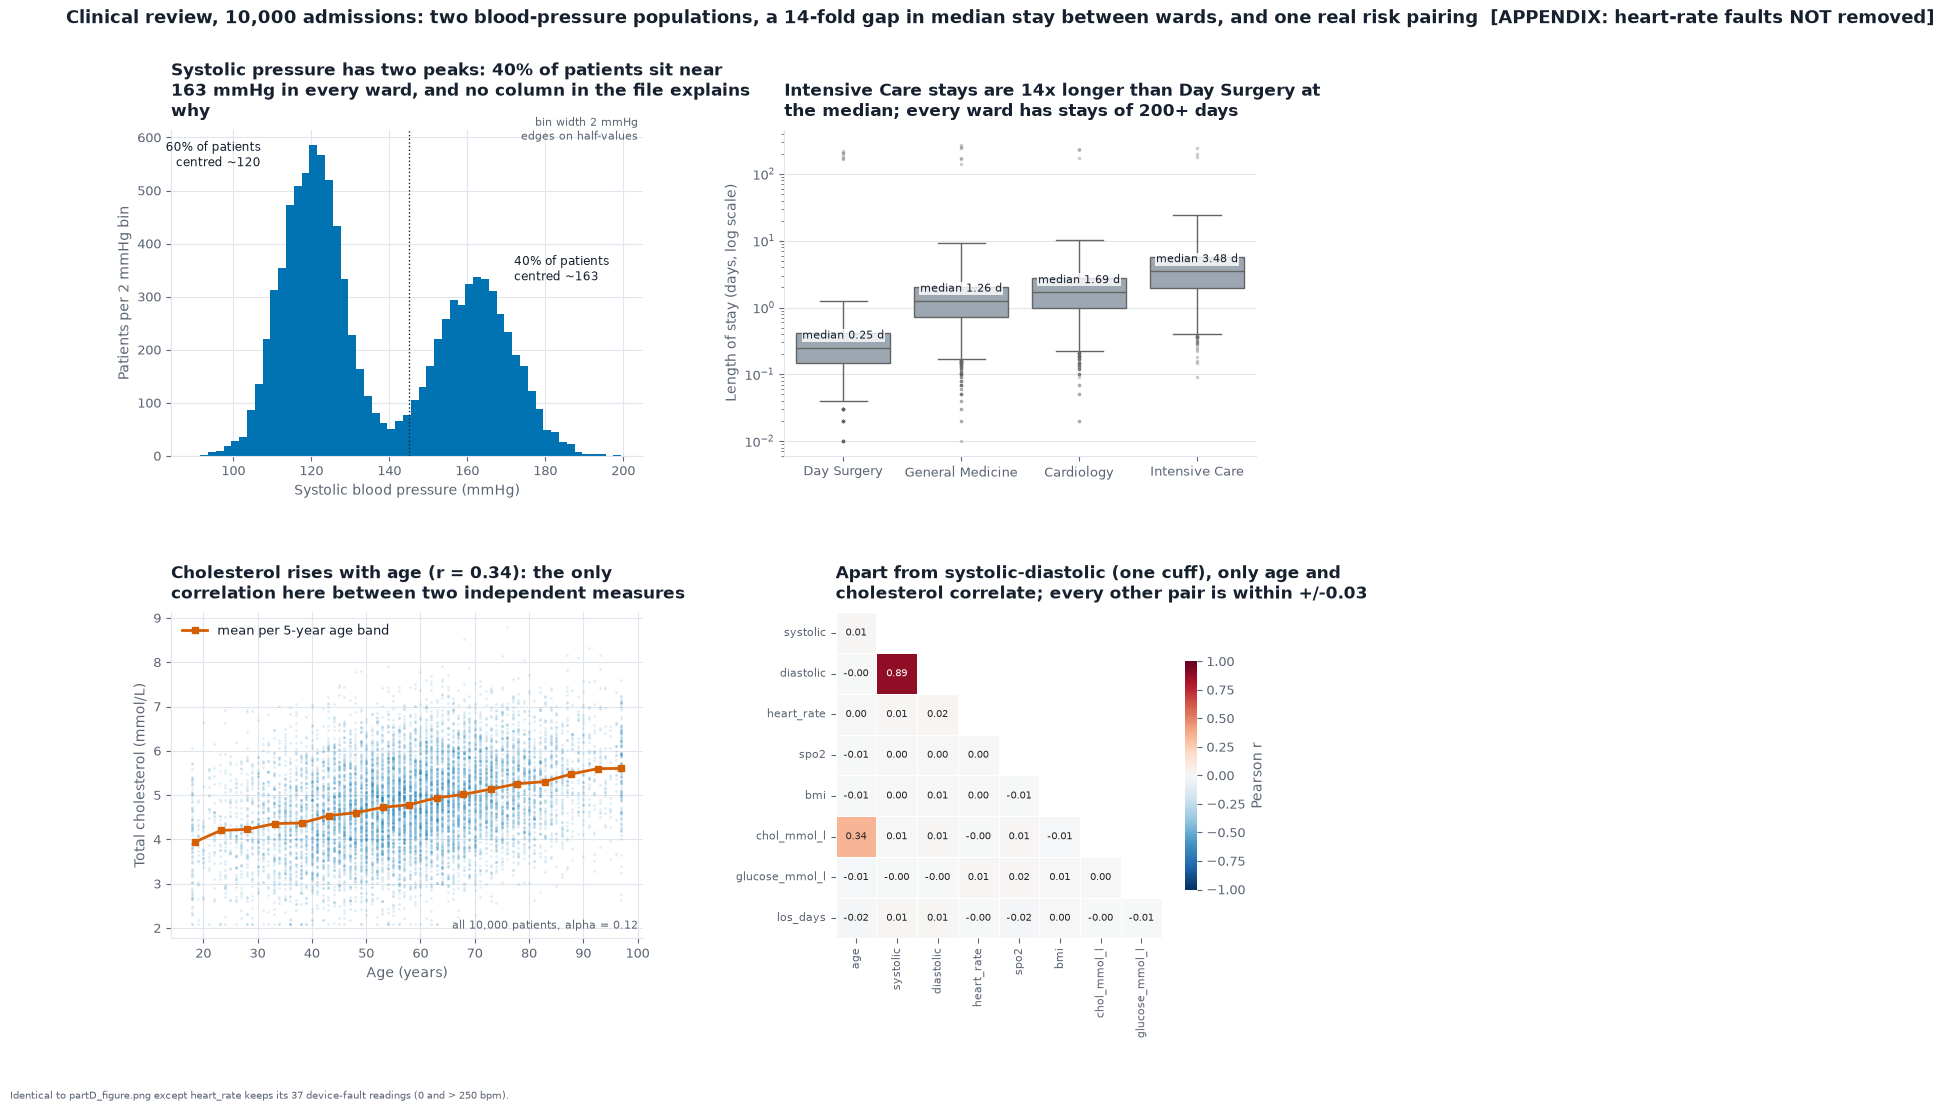

In [11]:
fig_raw = build_figure(df, hr_col="heart_rate_raw", label="  [APPENDIX: heart-rate faults NOT removed]")
save_fig(fig_raw, CHARTS / "partD_appendix_no_exclusion.png",
         note="Identical to partD_figure.png except heart_rate keeps its 37 device-fault readings (0 and > 250 bpm).")
raw_r = df[HEAT].assign(heart_rate=df.heart_rate_raw).corr()["heart_rate"].drop("heart_rate")
clean_r = df[HEAT].corr()["heart_rate"].drop("heart_rate")
print("heart_rate correlations, raw vs cleaned (largest absolute change):",
      f"{(raw_r - clean_r).abs().max():.3f}")

Removing the 37 faults changes no heart-rate correlation by more than a few hundredths, and every panel's
conclusion is the same in both versions. The rule doesn't help my conclusion, which is what Part E's
symmetry test asks.

## 6 · Does the finished figure survive colour-blindness?

Part C's optional check: simulate deuteranopia on the rendered PNG itself, not just on the palette.

'charts\\partD_cvd_check.png'

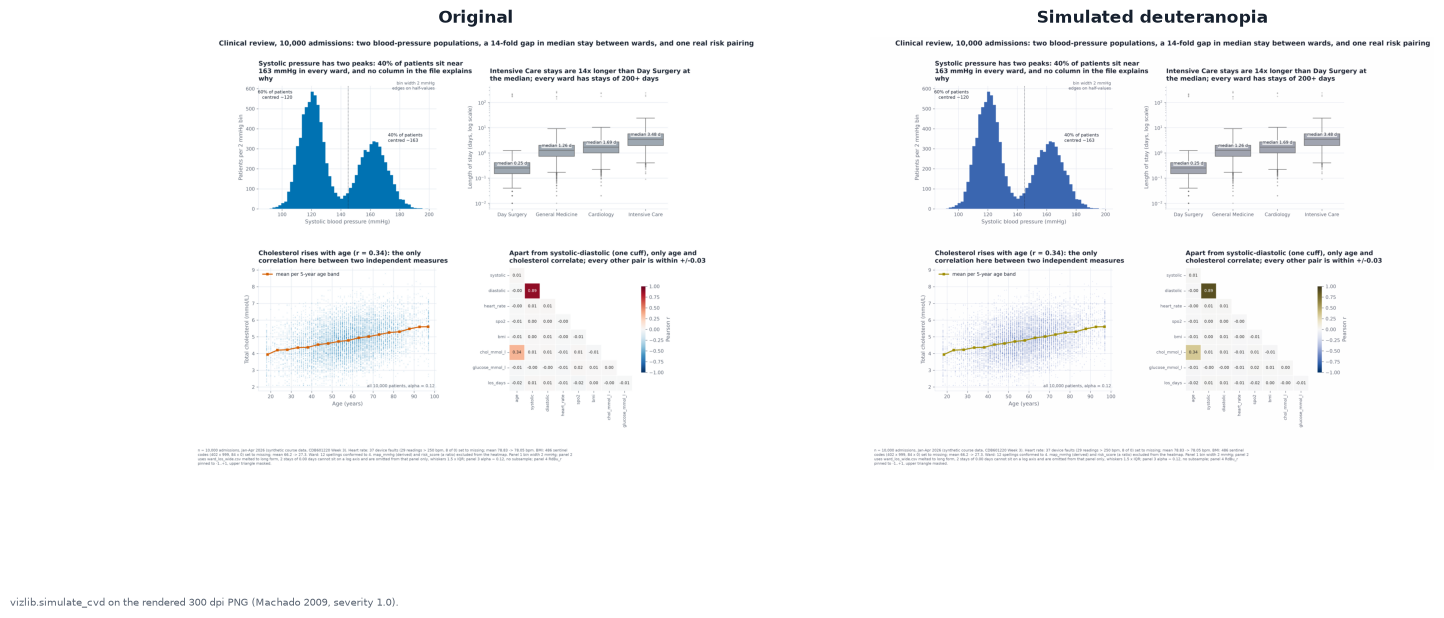

In [12]:
img = mpimg.imread(CHARTS / "partD_figure.png")[..., :3]
sim = simulate_cvd(img, "deutan")
fig, (l, r) = plt.subplots(1, 2, figsize=(16, 6.5))
l.imshow(img)
l.set_title("Original", loc="center")
r.imshow(np.clip(sim, 0, 1))
r.set_title("Simulated deuteranopia", loc="center")
for x in (l, r):
    x.axis("off")
save_fig(fig, CHARTS / "partD_cvd_check.png", note="vizlib.simulate_cvd on the rendered 300 dpi PNG (Machado 2009, severity 1.0).")

Under deuteranopia, the blue histogram and scatter stay blue, the orange age-band line turns olive but
stays clearly separate from the blue cloud (and also has square markers and a legend), and the heatmap's
blue–red diverging ramp keeps its sign as blue against yellow-brown. Nothing in the figure relies on a red
vs green distinction.